# Investigación · ¿El defecto nace en el MC4 o en el Skinpass?
**Pregunta.** Cuando una pieza sale con defecto del Skinpass, ¿la causa viene del Molino Caliente 4 (MC4) o la genera el propio Skinpass?

**Cómo lo medimos.** Cada defecto que registra el Skinpass trae la columna `Linea Origen`, que dice qué línea lo provocó:
- `MC4_PSQ`: el defecto viene del molino caliente y el Skinpass solo lo detecta.
- `SKP_PSQ`: el defecto lo genera el Skinpass.

Además, ligamos cada pieza del Skinpass con su rollo del MC4 (`Material Entrada` = `Material Salida`) para ver si el MC4 ya lo había registrado.

**Pasos**
1. Cargar y ligar MC4 con Skinpass.
2. Contar los defectos del Skinpass por línea de origen: todos y los que retienen la pieza.
3. Atribuir cada pieza retenida en el Skinpass a su origen.
4. Revisar si los defectos heredados del MC4 ya estaban registrados en el MC4.
5. Figura comparativa y conclusión.

## 0. Configuración

In [36]:
# Solo en Colab: descarga el repo (datos incluidos) e instala dependencias. En local no hace nada.
import os, sys, subprocess
if 'google.colab' in sys.modules:
    REPO = '/content/Entregable_Reto'
    if not os.path.exists(REPO):
        subprocess.run(['git', 'clone', '-q', 'https://github.com/DiegoLarrieta/Entregable_Reto.git', REPO], check=True)
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', f'{REPO}/requirements.txt'], check=True)
    os.chdir(f'{REPO}/notebooks')

In [37]:
# Configuración: busca la carpeta del repo para poder importar src/ternium.py.
import sys
from pathlib import Path
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'ternium.py').exists())
sys.path.append(str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.ternium import *

estilo()
pd.set_option('display.max_columns', 20)

## 1. Carga y liga MC4 → Skinpass
La unidad es la **pieza del Skinpass**. Un rollo del MC4 puede dividirse en varias piezas.

In [38]:
mc4 = cargar_mc4()
skp = cargar_skp()

ligada = skp['Material Entrada'].isin(mc4['Material Salida'])
print(f'MC4: {len(mc4):,} rollos · Skinpass: {len(skp):,} piezas')
print(f'Piezas del Skinpass ligadas a su rollo del MC4: {ligada.sum():,} ({ligada.mean():.1%})')

/content/Entregable_Reto/src/ternium.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return pd.concat(
/content/Entregable_Reto/src/ternium.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return pd.concat(


MC4: 149,734 rollos · Skinpass: 58,786 piezas
Piezas del Skinpass ligadas a su rollo del MC4: 57,099 (97.1%)


## 2. Defectos del Skinpass por línea de origen
Pasamos los 5 bloques `Defecto (k)` a formato largo: un renglón por defecto, con su línea de origen y su calificación (`Calidad (k)`: ACEPTADO, RETENIDO o REPROCESO).

In [39]:
def defectos_skp(skp):
    """Un renglón por defecto registrado en el Skinpass, con su línea de origen."""
    partes = []
    for k in range(1, 6):
        t = skp[['Material Entrada', f'Defecto ({k})', f'Linea Origen ({k})', f'Calidad ({k})']].copy()
        t.columns = ['rollo', 'defecto', 'linea', 'calidad']
        t['pieza'] = skp.index
        partes.append(t.dropna(subset=['defecto']))
    D = pd.concat(partes, ignore_index=True)
    D['defecto'] = D['defecto'].str.rstrip('.')
    D['origen'] = np.select([D['linea'] == 'MC4_PSQ', D['linea'] == 'SKP_PSQ'], ['MC4', 'Skinpass'], 'Otra línea')
    D['retiene'] = D['calidad'] == 'RETENIDO'
    return D

D = defectos_skp(skp)
ORDEN = ['MC4', 'Skinpass', 'Otra línea']
tabla = pd.DataFrame({
    'Defectos': D['origen'].value_counts(),
    'Defectos que retienen': D.loc[D['retiene'], 'origen'].value_counts(),
}).reindex(ORDEN).fillna(0).astype(int)
tabla['% de defectos'] = (100 * tabla['Defectos'] / tabla['Defectos'].sum()).round(1)
tabla['% de los que retienen'] = (100 * tabla['Defectos que retienen'] / tabla['Defectos que retienen'].sum()).round(1)
tabla['% retiene dentro del origen'] = (100 * tabla['Defectos que retienen'] / tabla['Defectos']).round(1)
tabla

,Defectos,Defectos que retienen,% de defectos,% de los que retienen,% retiene dentro del origen
origen,,,,,
MC4,2806,2579,19.5,50.3,91.9
Skinpass,11561,2501,80.2,48.8,21.6
Otra línea,50,48,0.3,0.9,96.0


**Qué vemos.** Por número, la mayoría de los defectos se registran como generados en el Skinpass, pero casi todos se aceptan. Los que vienen del MC4 son menos y casi todos retienen la pieza. Contar defectos sin ver su gravedad exagera el papel del Skinpass.

## 3. ¿Qué origen tiene cada pieza retenida?
Una pieza está retenida si su `Dictamen` es RETENIDO. La atribuimos según la línea de origen de los defectos que la retuvieron:
- **MC4** o **Skinpass** si todos vienen de una sola línea;
- **Ambas** si tiene defectos que retienen de las dos.

In [40]:
def origen_pieza(origenes):
    if {'MC4', 'Skinpass'} <= origenes:
        return 'Ambas'
    for o in ('MC4', 'Skinpass'):
        if o in origenes:
            return o
    return 'Otra línea'

retenidas = skp.index[skp['Dictamen'] == 'RETENIDO']
atrib = (D[D['retiene']].groupby('pieza')['origen'].agg(set).map(origen_pieza)
         .reindex(retenidas).fillna('Sin defecto registrado'))
piezas = atrib.value_counts().reindex(['MC4', 'Skinpass', 'Ambas', 'Otra línea', 'Sin defecto registrado']).fillna(0).astype(int)
print(f'Piezas retenidas en el Skinpass: {len(retenidas):,} de {len(skp):,} ({len(retenidas)/len(skp):.1%})')
pd.DataFrame({'Piezas': piezas, '%': (100 * piezas / piezas.sum()).round(1)})

Piezas retenidas en el Skinpass: 4,415 de 58,786 (7.5%)


,Piezas,%
origen,,
MC4,2128,48.2
Skinpass,2053,46.5
Ambas,218,4.9
Otra línea,16,0.4
Sin defecto registrado,0,0.0


**Qué vemos.** Las piezas que se retienen en el Skinpass se reparten casi a la mitad: una parte por defectos heredados del MC4 y otra por defectos que genera el propio Skinpass. Ninguna de las dos líneas explica sola el problema.

In [41]:
# Qué defectos retienen piezas, por origen (los 10 más frecuentes)
top = (D[D['retiene']].groupby(['defecto', 'origen']).size().unstack(fill_value=0)
       .reindex(columns=ORDEN, fill_value=0))
top = top.loc[top.sum(axis=1).sort_values(ascending=False).index[:10]]
top

origen,MC4,Skinpass,Otra línea
defecto,,,
PESO (-),959,445,26
PESO (+),889,272,1
ESPESOR (+/-),1,1052,0
MAL ENROLLADO,11,267,0
ANCHO (-),274,0,1
ANCHO (+),165,2,13
MARCAS,23,90,0
% ELONGACIÓN TEMPLES (+/-),0,100,0
TABLEADO,35,26,0


**Qué vemos.** Cada línea tiene su propio tipo de defecto. Del MC4 vienen sobre todo los de **peso** y **ancho** (dimensiones que el Skinpass no puede corregir); del Skinpass, los de **espesor**, **mal enrollado** y **% de elongación** (cómo se lamina y enrolla en esa línea). El peso fuera de tolerancia aparece en ambas, pero sobre todo con origen MC4.

## 4. Los defectos heredados del MC4, ¿ya estaban registrados en el MC4?
Para cada defecto con origen MC4 que encontró el Skinpass, buscamos si ese mismo defecto ya aparecía en el rollo del MC4.

In [7]:
reg_mc4 = set()
for k in range(1, 6):
    t = mc4[['Material Salida', f'Defecto ({k})']].dropna()
    reg_mc4 |= set(zip(t['Material Salida'], t[f'Defecto ({k})'].str.rstrip('.')))

H = D[D['origen'] == 'MC4'].copy()
H['ya_en_mc4'] = [(r, d) in reg_mc4 for r, d in zip(H['rollo'], H['defecto'])]
print(f'Defectos de origen MC4 detectados en el Skinpass: {len(H):,}')
print(f'Ya registrados en el MC4: {H["ya_en_mc4"].mean():.1%} · No registrados en el MC4: {1 - H["ya_en_mc4"].mean():.1%}')
H.groupby('defecto')['ya_en_mc4'].agg(defectos='size', ya_en_mc4='mean').sort_values('defectos', ascending=False).head(8).round(2)

Defectos de origen MC4 detectados en el Skinpass: 2,806
Ya registrados en el MC4: 18.7% · No registrados en el MC4: 81.3%


,defectos,ya_en_mc4
defecto,,
PESO (-),959,0.15
PESO (+),890,0.28
ANCHO (-),277,0.00
ANCHO (+),165,0.00
TENSIÓN DE ENROLLADO,94,0.00
SOMBRAS,44,0.11
TABLEADO,41,0.00
MALTRATO,38,0.00


**Qué vemos.** La mayoría de los defectos que el Skinpass atribuye al MC4 **no aparecían registrados en el MC4**. El defecto nace en el molino caliente, pero se detecta hasta el Skinpass, días después.

## 5. Figura: MC4 contra Skinpass

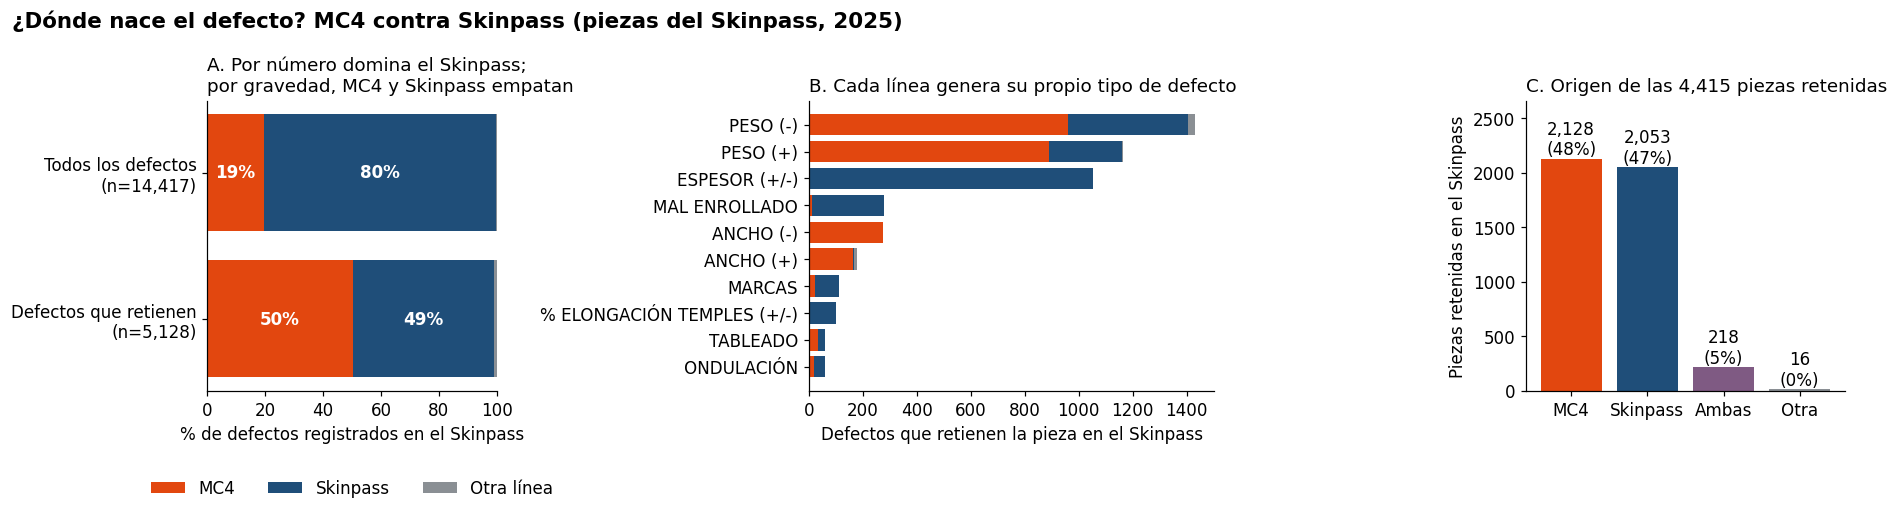

In [8]:
C = {'MC4': COLORES['naranja'], 'Skinpass': COLORES['azul'], 'Ambas': '#7f5a83',
     'Otra línea': COLORES['gris'], 'Sin defecto registrado': '#d0d3d6'}
fig, ax = plt.subplots(1, 3, figsize=(17, 5.4), gridspec_kw={'width_ratios': [1, 1.4, 1.1]})

# A. Todos los defectos vs. los que retienen
a = ax[0]
for j, col in enumerate(['Defectos', 'Defectos que retienen']):
    izq = 0
    tot = tabla[col].sum()
    for o in ORDEN:
        v = 100 * tabla.loc[o, col] / tot
        a.barh(j, v, left=izq, color=C[o], label=o if j == 0 else None)
        if v > 6:
            a.text(izq + v / 2, j, f'{v:.0f}%', ha='center', va='center', color='white', fontweight='bold')
        izq += v
a.set_yticks([0, 1], [f'Todos los defectos\n(n={tabla["Defectos"].sum():,})',
                      f'Defectos que retienen\n(n={tabla["Defectos que retienen"].sum():,})'])
a.invert_yaxis(); a.set_xlim(0, 100); a.set_xlabel('% de defectos registrados en el Skinpass')
a.set_title('A. Por número domina el Skinpass;\npor gravedad, MC4 y Skinpass empatan')
a.legend(loc='lower center', bbox_to_anchor=(0.5, -0.42), ncol=3)

# B. Defectos que retienen, por tipo y origen
b = ax[1]
t = top.iloc[::-1]
izq = np.zeros(len(t))
for o in ORDEN:
    b.barh(t.index, t[o], left=izq, color=C[o])
    izq += t[o].values
b.set_xlabel('Defectos que retienen la pieza en el Skinpass')
b.set_title('B. Cada línea genera su propio tipo de defecto')

# C. Piezas retenidas por origen
c = ax[2]
p = piezas[piezas > 0]
c.bar(range(len(p)), p.values, color=[C[i] for i in p.index])
for i, v in enumerate(p.values):
    c.text(i, v, f'{v:,}\n({100 * v / p.sum():.0f}%)', ha='center', va='bottom')
c.set_xticks(range(len(p)), [{'Otra línea': 'Otra'}.get(i, i) for i in p.index])
c.set_ylabel('Piezas retenidas en el Skinpass'); c.set_ylim(0, p.max() * 1.25)
c.set_title(f'C. Origen de las {p.sum():,} piezas retenidas')

fig.suptitle('¿Dónde nace el defecto? MC4 contra Skinpass (piezas del Skinpass, 2025)', x=0.01, ha='left', fontsize=14, fontweight='bold')
fig.tight_layout()
guardar(fig, 'fig4_origen_defectos')
plt.show()

## Conclusión
1. **No hay una sola causa raíz: el problema se reparte entre las dos líneas.** De las piezas que el Skinpass retiene, cerca de la mitad es por defectos heredados del MC4 y la otra mitad por defectos generados en el Skinpass.
2. **Por gravedad pesa más el MC4 de lo que sugiere el conteo.** El Skinpass registra muchos más defectos, pero la mayoría se aceptan. Los del MC4 son pocos, pero casi todos retienen la pieza.
3. **Cada línea tiene sus defectos.** Del MC4 vienen peso y ancho fuera de tolerancia; del Skinpass, espesor, mal enrollado y elongación. Atacarlos pide acciones distintas en cada línea.
4. **El MC4 no ve la mayoría de lo que hereda.** La mayoría de los defectos de origen MC4 que detecta el Skinpass no estaban registrados en el MC4: se descubren días después, cuando la pieza ya tiene costo de proceso.

**Límites.** `Linea Origen` es la atribución que registra la planta (sistema o inspector), no una prueba causal. Los defectos dimensionales (peso, ancho, espesor) son reglas automáticas contra una tolerancia (ver `02_calidad`), así que describen *dónde se midió fuera de rango* más que un mecanismo físico.